In [24]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input

from sklearn.model_selection import train_test_split
from collections import defaultdict
from tqdm import tqdm
import keras_cv

In [25]:
DATA_DIR = "Skin Disease Dataset"
IMG_SIZE = 224
INPUT_SHAPE = (224, 224, 3)
BATCH_SIZE = 32

In [26]:
classes = sorted(os.listdir(DATA_DIR))
num_classes = len(classes)

print("Classes:", classes)
print("Number of classes:", num_classes)

Classes: ['Acitinic Keratosis', 'Dermatofibroma', 'Nevus', 'Pigmented Benign Keratosis', 'Seborrheic Keratosis', 'Vascular Lesion']
Number of classes: 6


In [27]:
data_dict = defaultdict(list)
root_images = []
root_labels = []
error_count = 0

for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)
    images = os.listdir(class_path)

    for img_name in tqdm(images, desc=f"Loading {class_name}"):
        try:
            img_path = os.path.join(class_path, img_name)
            image = cv2.imread(img_path)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            data_dict[class_name].append(image)
            root_images.append(image)
            root_labels.append(class_name)
        except:
            error_count += 1

print("Errors:", error_count)
print("Total images loaded:", len(root_images))

Loading Vascular Lesion: 100%|██████████| 290/290 [00:03<00:00, 80.47it/s] 

Errors: 2
Total images loaded: 2688


Acitinic Keratosis            500
Nevus                         500
Pigmented Benign Keratosis    500
Seborrheic Keratosis          500
Dermatofibroma                399
Vascular Lesion               289
dtype: int64


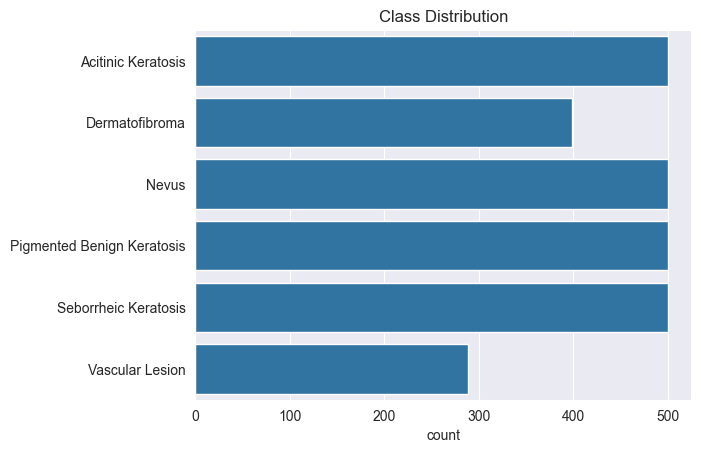

In [28]:
label_counts = pd.Series(root_labels).value_counts()
print(label_counts)

sns.countplot(y=root_labels)
plt.title("Class Distribution")
plt.show()


Acitinic Keratosis            500
Nevus                         500
Pigmented Benign Keratosis    500
Seborrheic Keratosis          500
Dermatofibroma                399
Vascular Lesion               289
dtype: int64


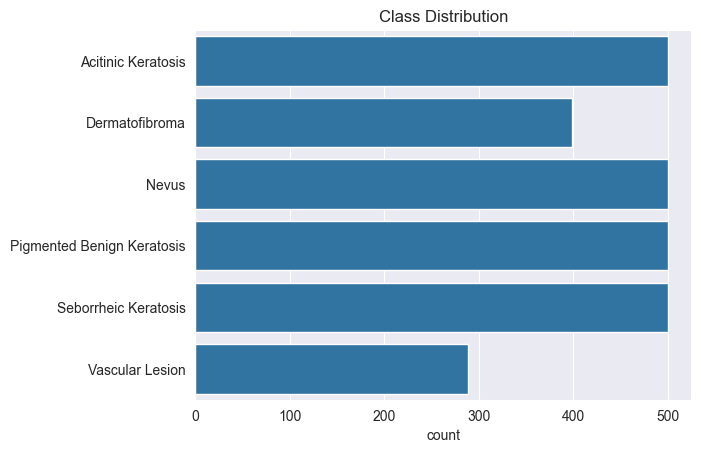

In [29]:
label_counts = pd.Series(root_labels).value_counts()
print(label_counts)

sns.countplot(y=root_labels)
plt.title("Class Distribution")
plt.show()


In [30]:
x_arr = np.array(root_images, dtype=np.float32)

y_arr = tf.one_hot(
    [classes.index(lbl) for lbl in root_labels],
    num_classes
).numpy()

print(x_arr.shape, y_arr.shape)


(2688, 224, 224, 3) (2688, 6)


In [31]:
image_per_class = 1000
mix_per_batch = 42

mixup = keras_cv.layers.Augmenter([keras_cv.layers.MixUp()])

root_label_df = pd.DataFrame({"dx": root_labels})
count_dict = {label: len(imgs) for label, imgs in data_dict.items()}

x_tensor = tf.constant(x_arr)
y_tensor = tf.constant(y_arr)

x_tensor_mix, y_tensor_mix = None, None

for label, count in count_dict.items():
    num_mix = ((image_per_class - count) // mix_per_batch) * mix_per_batch

    for _ in range(num_mix // mix_per_batch):
        idx = np.random.choice(
            root_label_df[root_label_df.dx == label].index,
            mix_per_batch,
            replace=False
        )

        mix_out = mixup({
            "images": tf.gather(x_tensor, idx),
            "labels": tf.gather(y_tensor, idx)
        })

        if x_tensor_mix is None:
            x_tensor_mix = mix_out["images"]
            y_tensor_mix = mix_out["labels"]
        else:
            x_tensor_mix = tf.concat([x_tensor_mix, mix_out["images"]], axis=0)
            y_tensor_mix = tf.concat([y_tensor_mix, mix_out["labels"]], axis=0)

x = np.concatenate([x_arr, x_tensor_mix.numpy()], axis=0)
y = np.concatenate([y_arr, y_tensor_mix.numpy()], axis=0)

print(x.shape, y.shape)


(5796, 224, 224, 3) (5796, 6)


In [32]:
x = preprocess_input(x)

In [33]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)


In [34]:
from tensorflow.keras import layers

# -------------------------------
# Channel Attention
# -------------------------------
def channel_attention(input_feature, ratio=8):
    channel = input_feature.shape[-1]

    shared_dense_1 = layers.Dense(channel // ratio, activation='relu')
    shared_dense_2 = layers.Dense(channel)

    avg_pool = layers.GlobalAveragePooling2D()(input_feature)
    avg_pool = layers.Reshape((1, 1, channel))(avg_pool)
    avg_pool = shared_dense_2(shared_dense_1(avg_pool))

    max_pool = layers.GlobalMaxPooling2D()(input_feature)
    max_pool = layers.Reshape((1, 1, channel))(max_pool)
    max_pool = shared_dense_2(shared_dense_1(max_pool))

    attention = layers.Activation('sigmoid')(avg_pool + max_pool)
    return layers.Multiply()([input_feature, attention])


# -------------------------------
# Spatial Attention (FIXED)
# -------------------------------
def spatial_attention(input_feature):
    avg_pool = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True)
    )(input_feature)

    max_pool = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True)
    )(input_feature)

    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])

    attention = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(concat)

    return layers.Multiply()([input_feature, attention])


# -------------------------------
# CBAM Block
# -------------------------------
def cbam_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x


In [35]:
from tensorflow.keras.applications import MobileNetV3Large

base_model = MobileNetV3Large(
    weights="imagenet",
    include_top=False,
    input_shape=INPUT_SHAPE
)

base_model.trainable = False  # Transfer learning

x = base_model.output
x = cbam_block(x)              # 🔥 CBAM ADDED HERE
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

output = layers.Dense(num_classes, activation="softmax")(x)

model = Model(base_model.input, output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ rescaling_1[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        144 │ activation_21[0]… │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        256 │ re_lu_19[0][0]    │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_add   │ (None, 112, 112,  │          0 │ activation_21[0]… │
│ (Add)               │ 16)               │            │ expanded_conv_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │      1,024 │ expanded_conv_ad… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │        256 │ expanded_conv_1_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 112, 112,  │          0 │ expanded_conv_1_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 113, 113,  │          0 │ re_lu_20[0][0]    │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        576 │ expanded_conv_1_… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        256 │ expanded_conv_1_

 Total params: 3,479,329 (13.27 MB)

 Trainable params: 481,057 (1.84 MB)

 Non-trainable params: 2,998,272 (11.44 MB)

In [36]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

Epoch 1/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 65s 394ms/step - accuracy: 0.2463 - loss: 2.0330 - val_accuracy: 0.5517 - val_loss: 1.4516
Epoch 2/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 53s 366ms/step - accuracy: 0.5566 - loss: 1.1883 - val_accuracy: 0.6914 - val_loss: 1.0183
Epoch 3/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 52s 360ms/step - accuracy: 0.6943 - loss: 0.8822 - val_accuracy: 0.7638 - val_loss: 0.7433
Epoch 4/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 53s 364ms/step - accuracy: 0.7347 - loss: 0.7096 - val_accuracy: 0.7914 - val_loss: 0.5915
Epoch 5/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 53s 362ms/step - accuracy: 0.8058 - loss: 0.5721 - val_accuracy: 0.8259 - val_loss: 0.5233
Epoch 6/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 51s 353ms/step - accuracy: 0.8426 - loss: 0.4856 - val_accuracy: 0.8448 - val_loss: 0.4556
Epoch 7/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 52s 359ms/step - accuracy: 0.8651 - loss: 0.4055 - val_accuracy: 0.8603 - val_loss: 0.4129
Epoch 8/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 58s 402ms/step - accuracy: 0.8813 - loss: 0

In [37]:
loss, acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", acc)

19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 346ms/step - accuracy: 0.9400 - loss: 0.1881
Test Accuracy: 0.9172413945198059


In [38]:
from sklearn.metrics import classification_report
y_pred = np.argmax(model.predict(x_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=classes))

19/19 ━━━━━━━━━━━━━━━━━━━━ 16s 536ms/step
                            precision    recall  f1-score   support

        Acitinic Keratosis       0.90      0.91      0.90        96
            Dermatofibroma       0.92      0.92      0.92        99
                     Nevus       0.96      0.95      0.95        96
Pigmented Benign Keratosis       0.87      0.92      0.89        96
      Seborrheic Keratosis       0.90      0.81      0.85        97
           Vascular Lesion       0.96      1.00      0.98        96

                  accuracy                           0.92       580
                 macro avg       0.92      0.92      0.92       580
              weighted avg       0.92      0.92      0.92       580



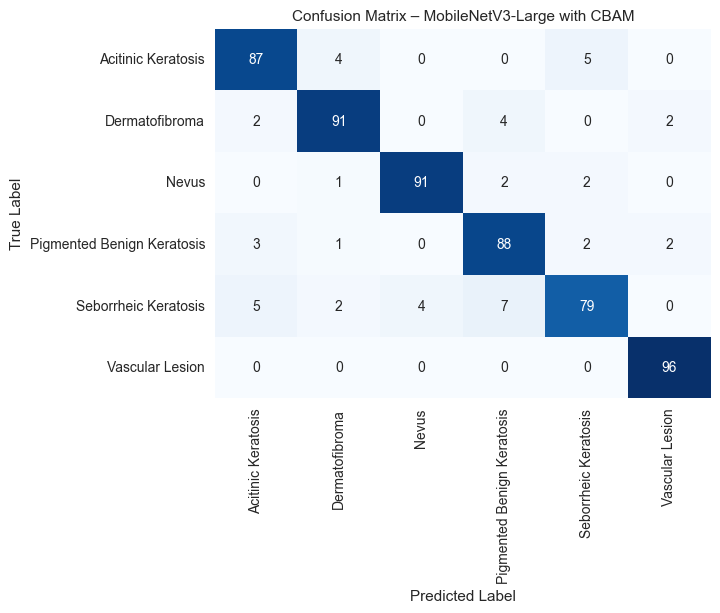

In [39]:
from sklearn.metrics  import confusion_matrix
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=classes,
            yticklabels=classes,
            cmap="Blues",
            cbar=False)
plt.title("Confusion Matrix – MobileNetV3-Large with CBAM", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
cbar=False
plt.show()


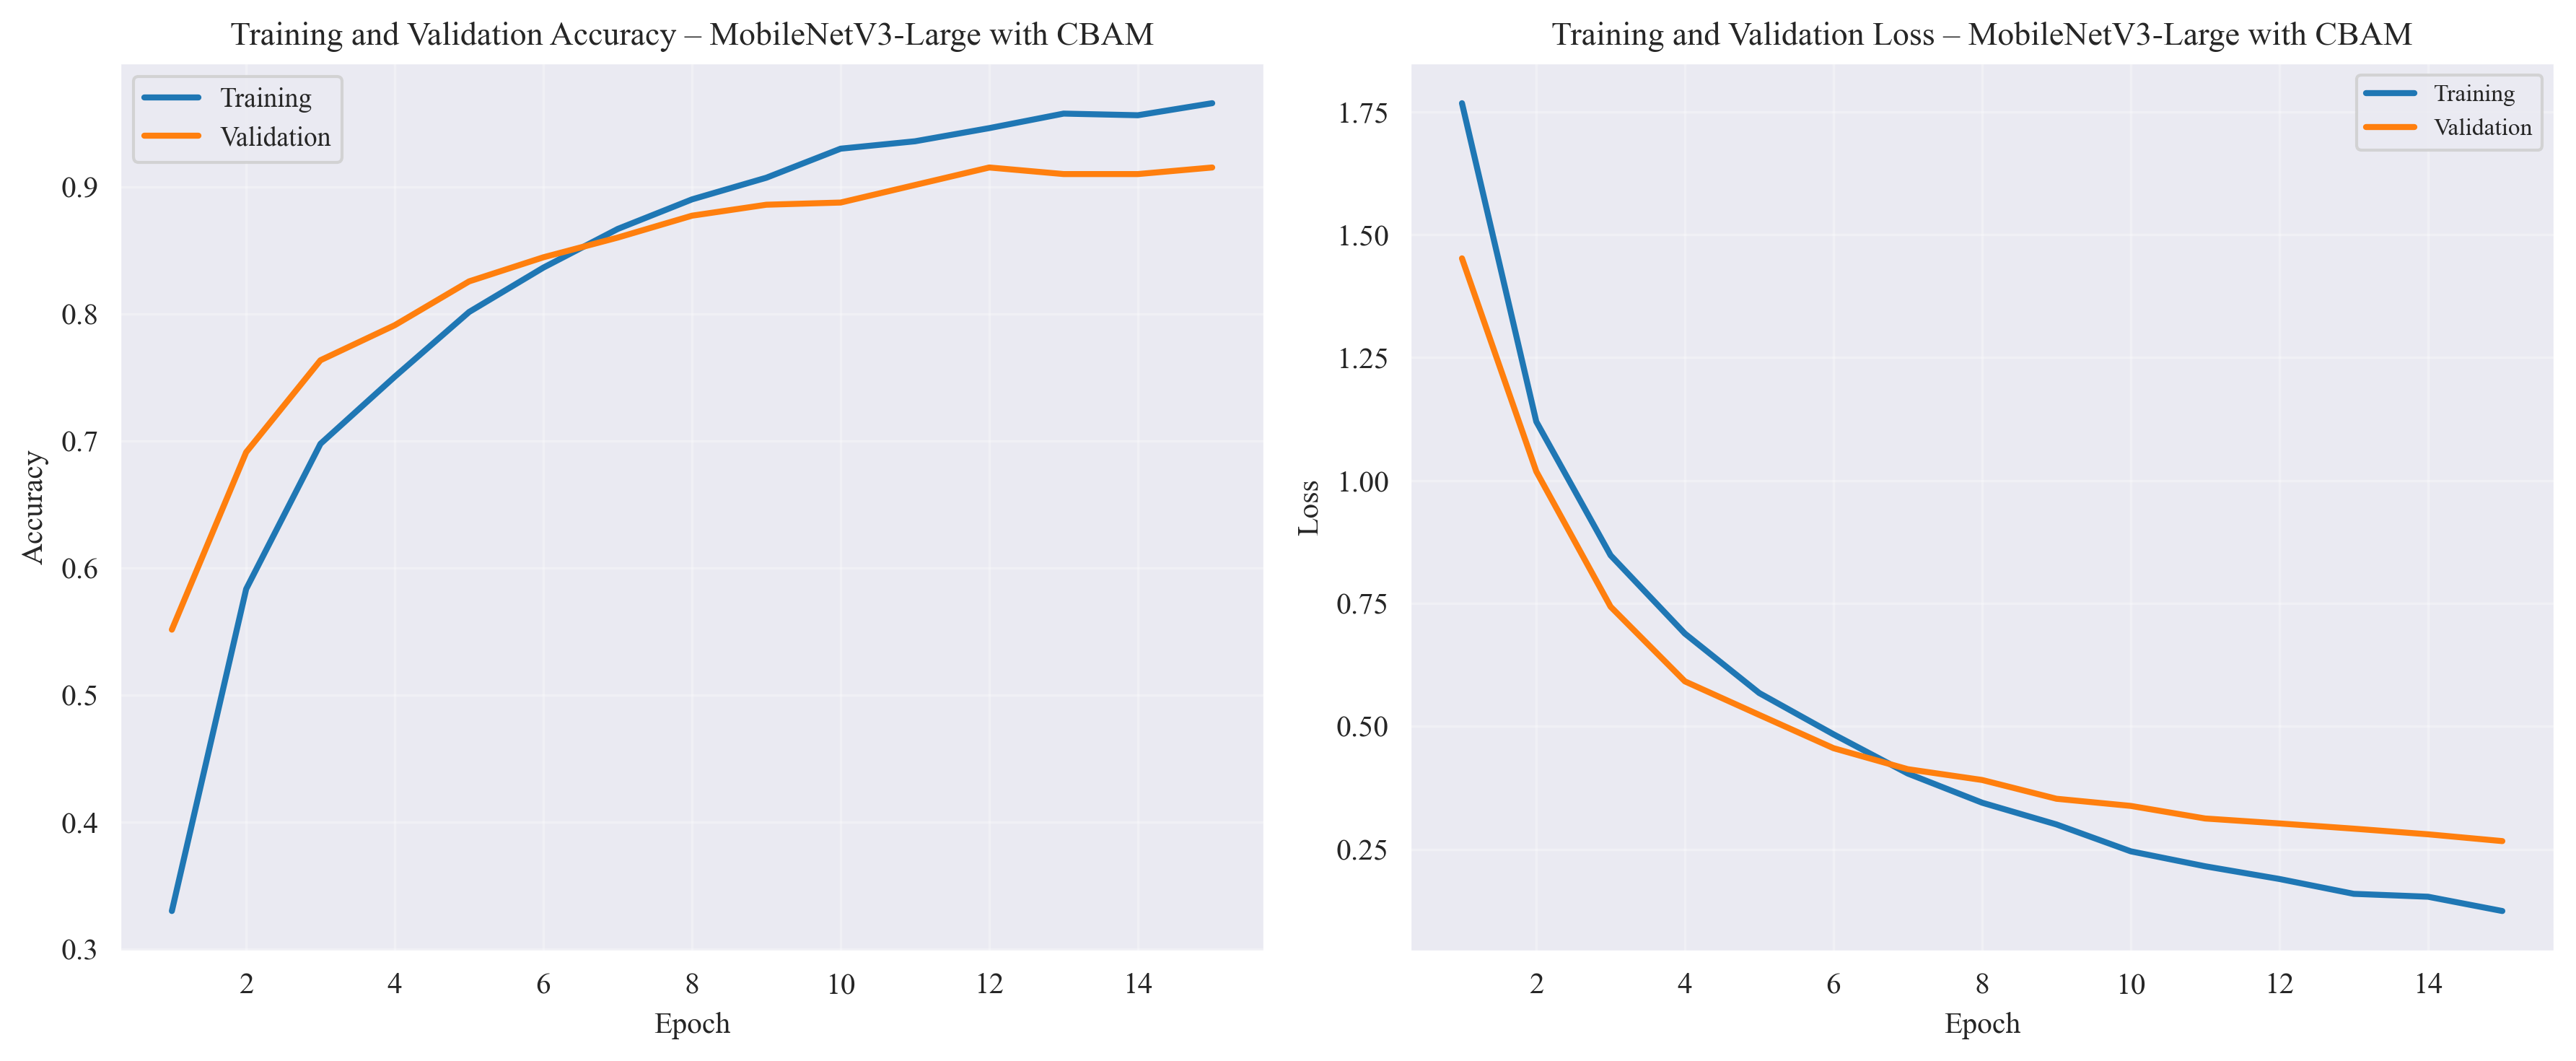

In [50]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(12, 5), dpi=300)
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 10

# ---------------- Accuracy Plot ----------------
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'],
         linewidth=2, label='Training')
plt.plot(epochs_range, history.history['val_accuracy'],
         linewidth=2, label='Validation')

plt.title("Training and Validation Accuracy – MobileNetV3-Large with CBAM", fontsize=11)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)

# ---------------- Loss Plot ----------------
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'],
         linewidth=2, label='Training')
plt.plot(epochs_range, history.history['val_loss'],
         linewidth=2, label='Validation')

plt.title("Training and Validation Loss – MobileNetV3-Large with CBAM", fontsize=11)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss", fontsize=10)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)

plt.tight_layout()

# Save high-resolution image for paper
plt.savefig("training_curves_mobilenetv3_cbam.png",
            dpi=300, bbox_inches='tight')

plt.show()


19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 394ms/step


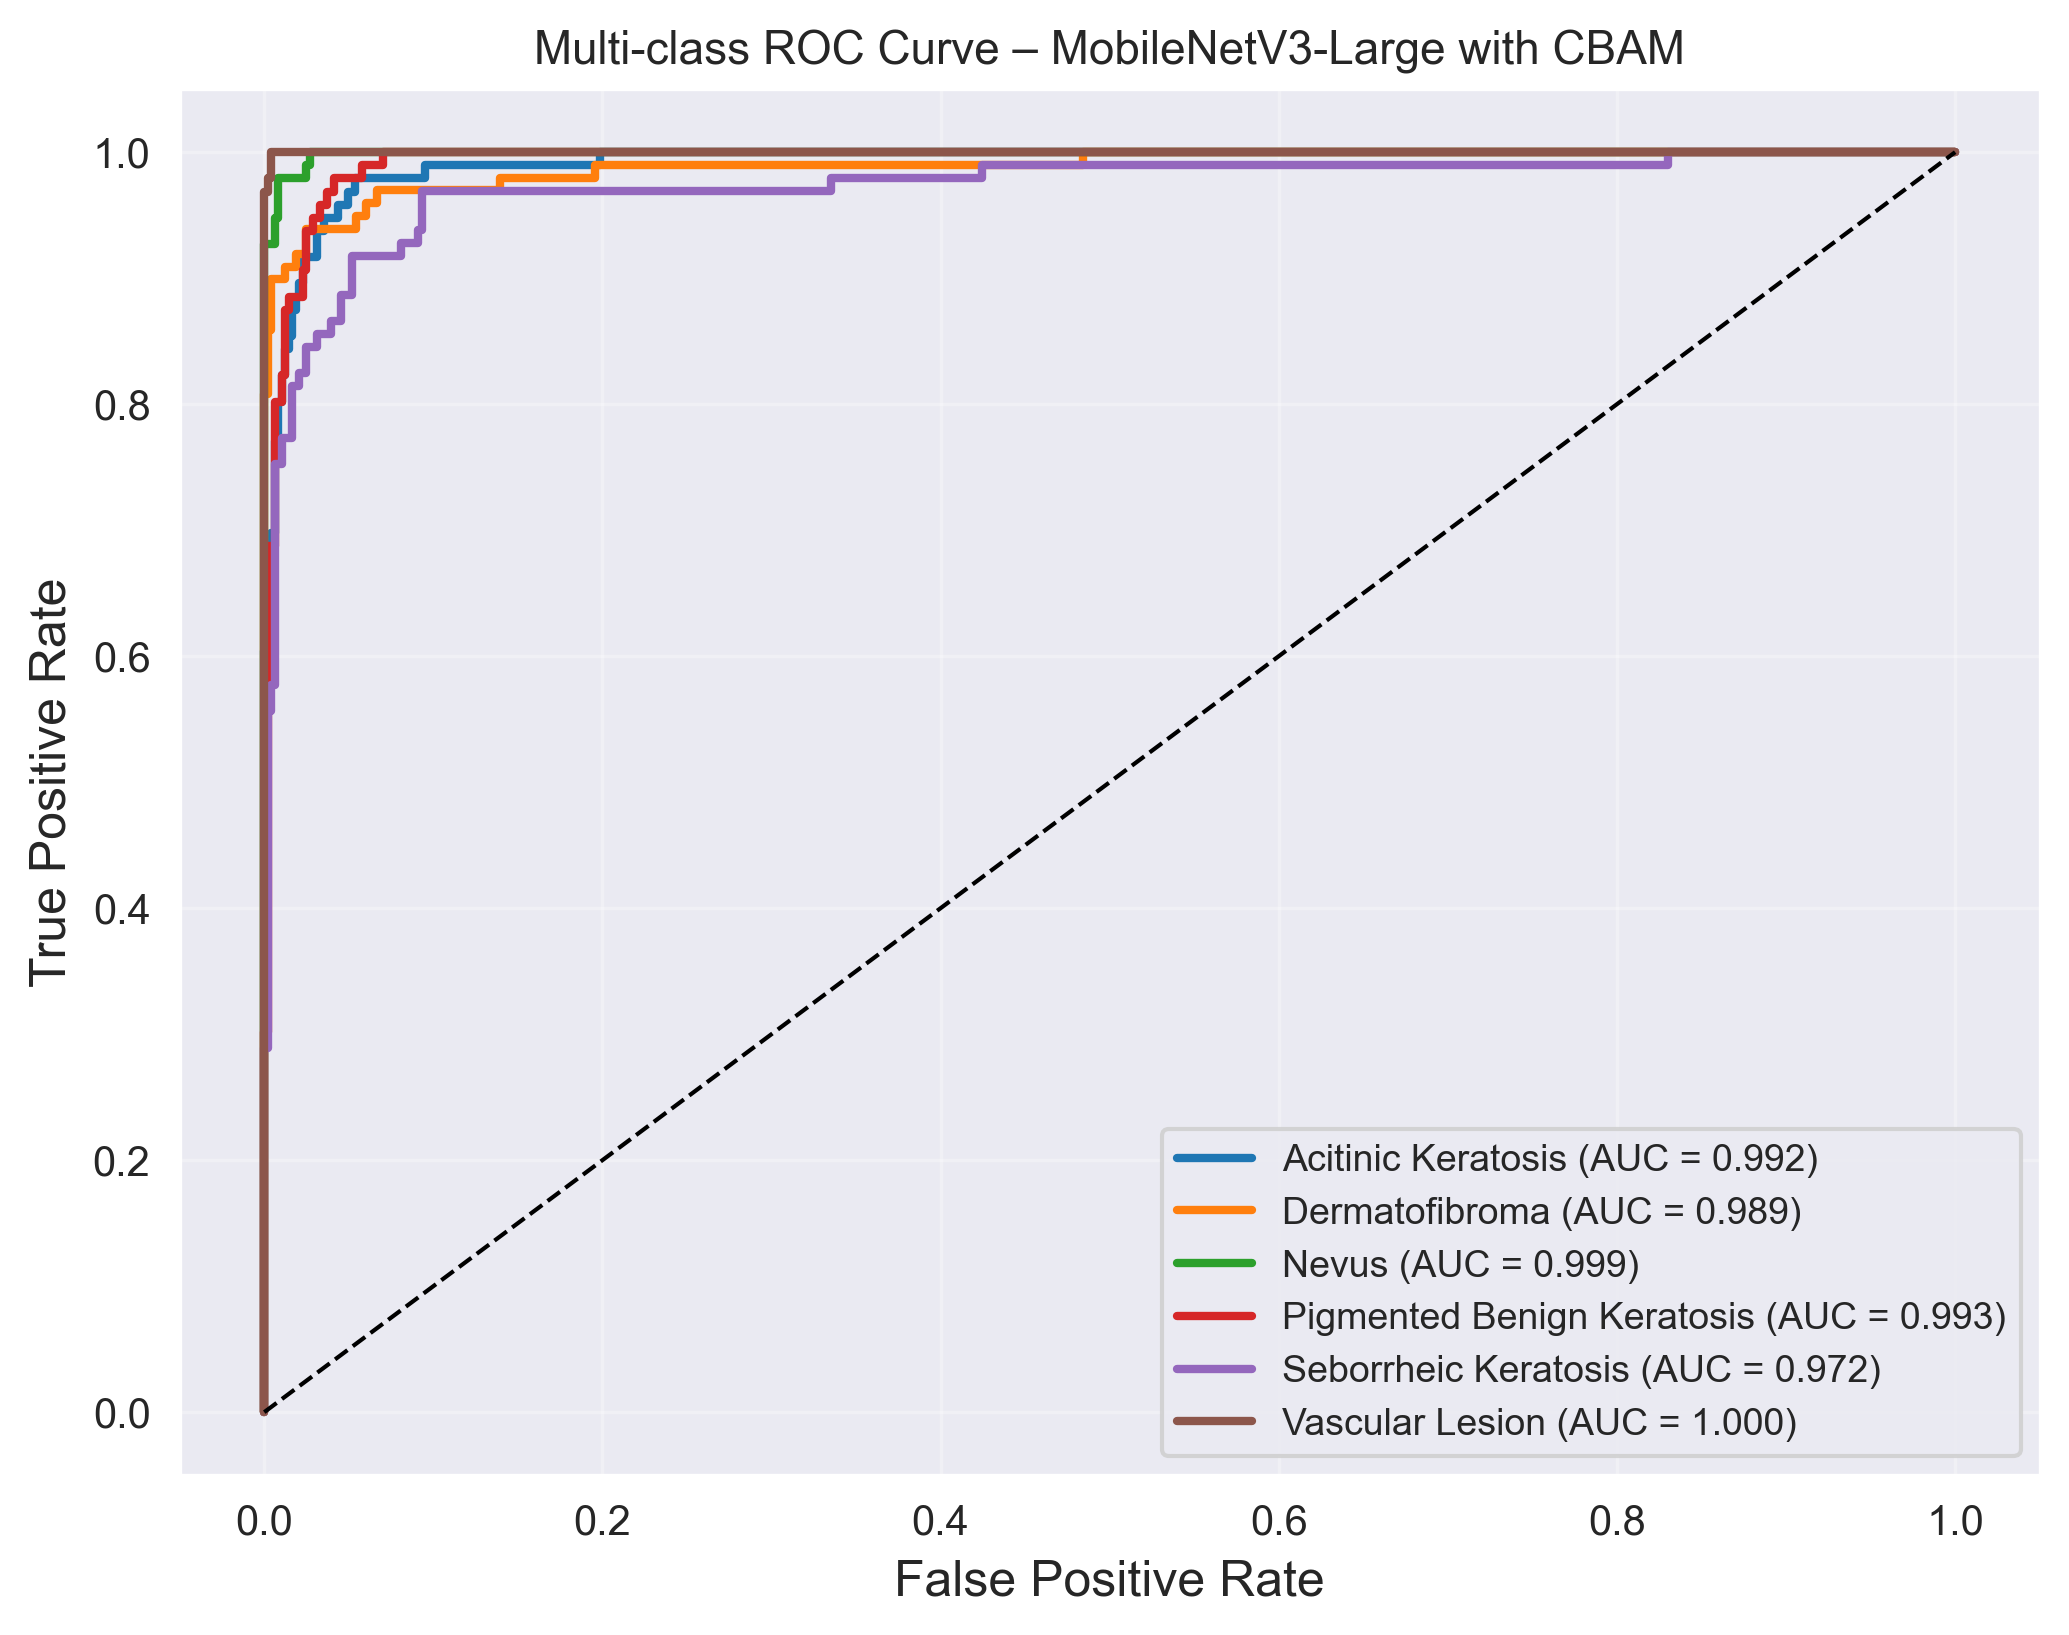

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Predict probabilities
y_score = model.predict(x_test)

# Convert true labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

y_true_bin = label_binarize(y_true, classes=range(n_classes))

# Compute ROC curve and AUC
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Create high-quality figure
plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], linewidth=2,
             label=f"{classes[i]} (AUC = {roc_auc[i]:.3f})")

# Random classifier
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("Multi-class ROC Curve – MobileNetV3-Large with CBAM", fontsize=11)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)

# Save for research paper
plt.savefig("roc_curve.png", dpi=300, bbox_inches='tight')

plt.show()


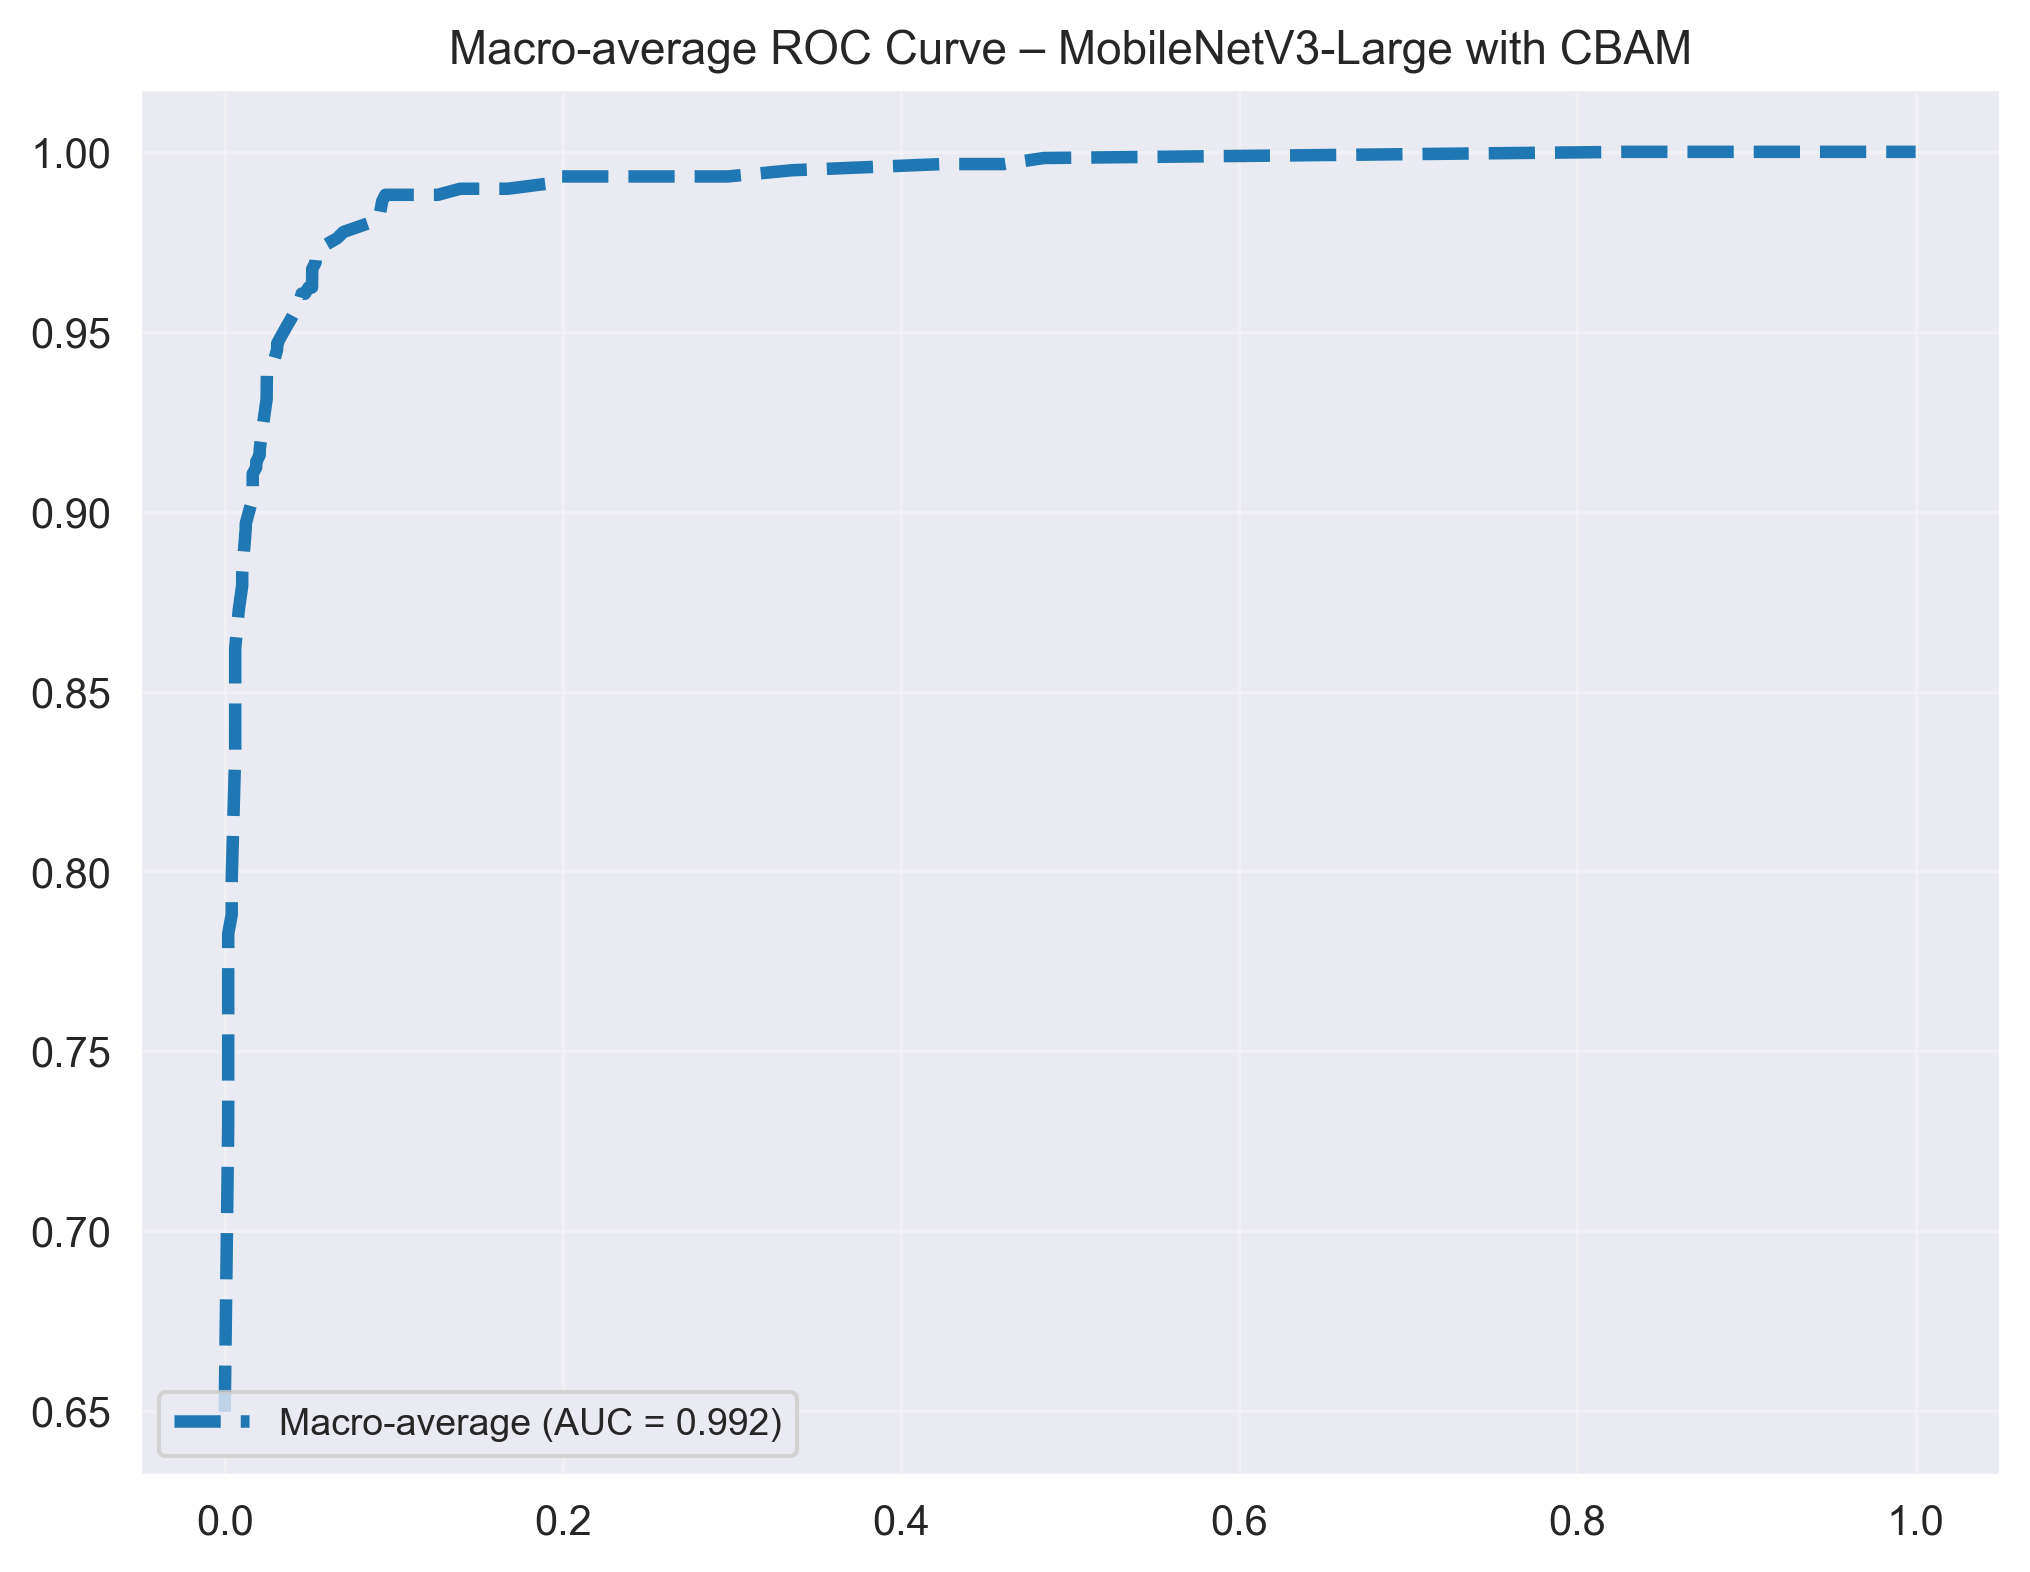

In [42]:
# Compute macro-average ROC
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)

for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= n_classes
macro_auc = auc(all_fpr, mean_tpr)
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(all_fpr, mean_tpr, linestyle='--', linewidth=3,
         label=f"Macro-average (AUC = {macro_auc:.3f})")
plt.title("Macro-average ROC Curve – MobileNetV3-Large with CBAM", fontsize=11)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

plt.show()

In [43]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(y_test, y_score, average='macro')
weighted_auc = roc_auc_score(y_test, y_score, average='weighted')

print("Macro AUC:", macro_auc)
print("Weighted AUC:", weighted_auc)


Macro AUC: 0.9908625788604065
Weighted AUC: 0.9908200072879096


19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 362ms/step


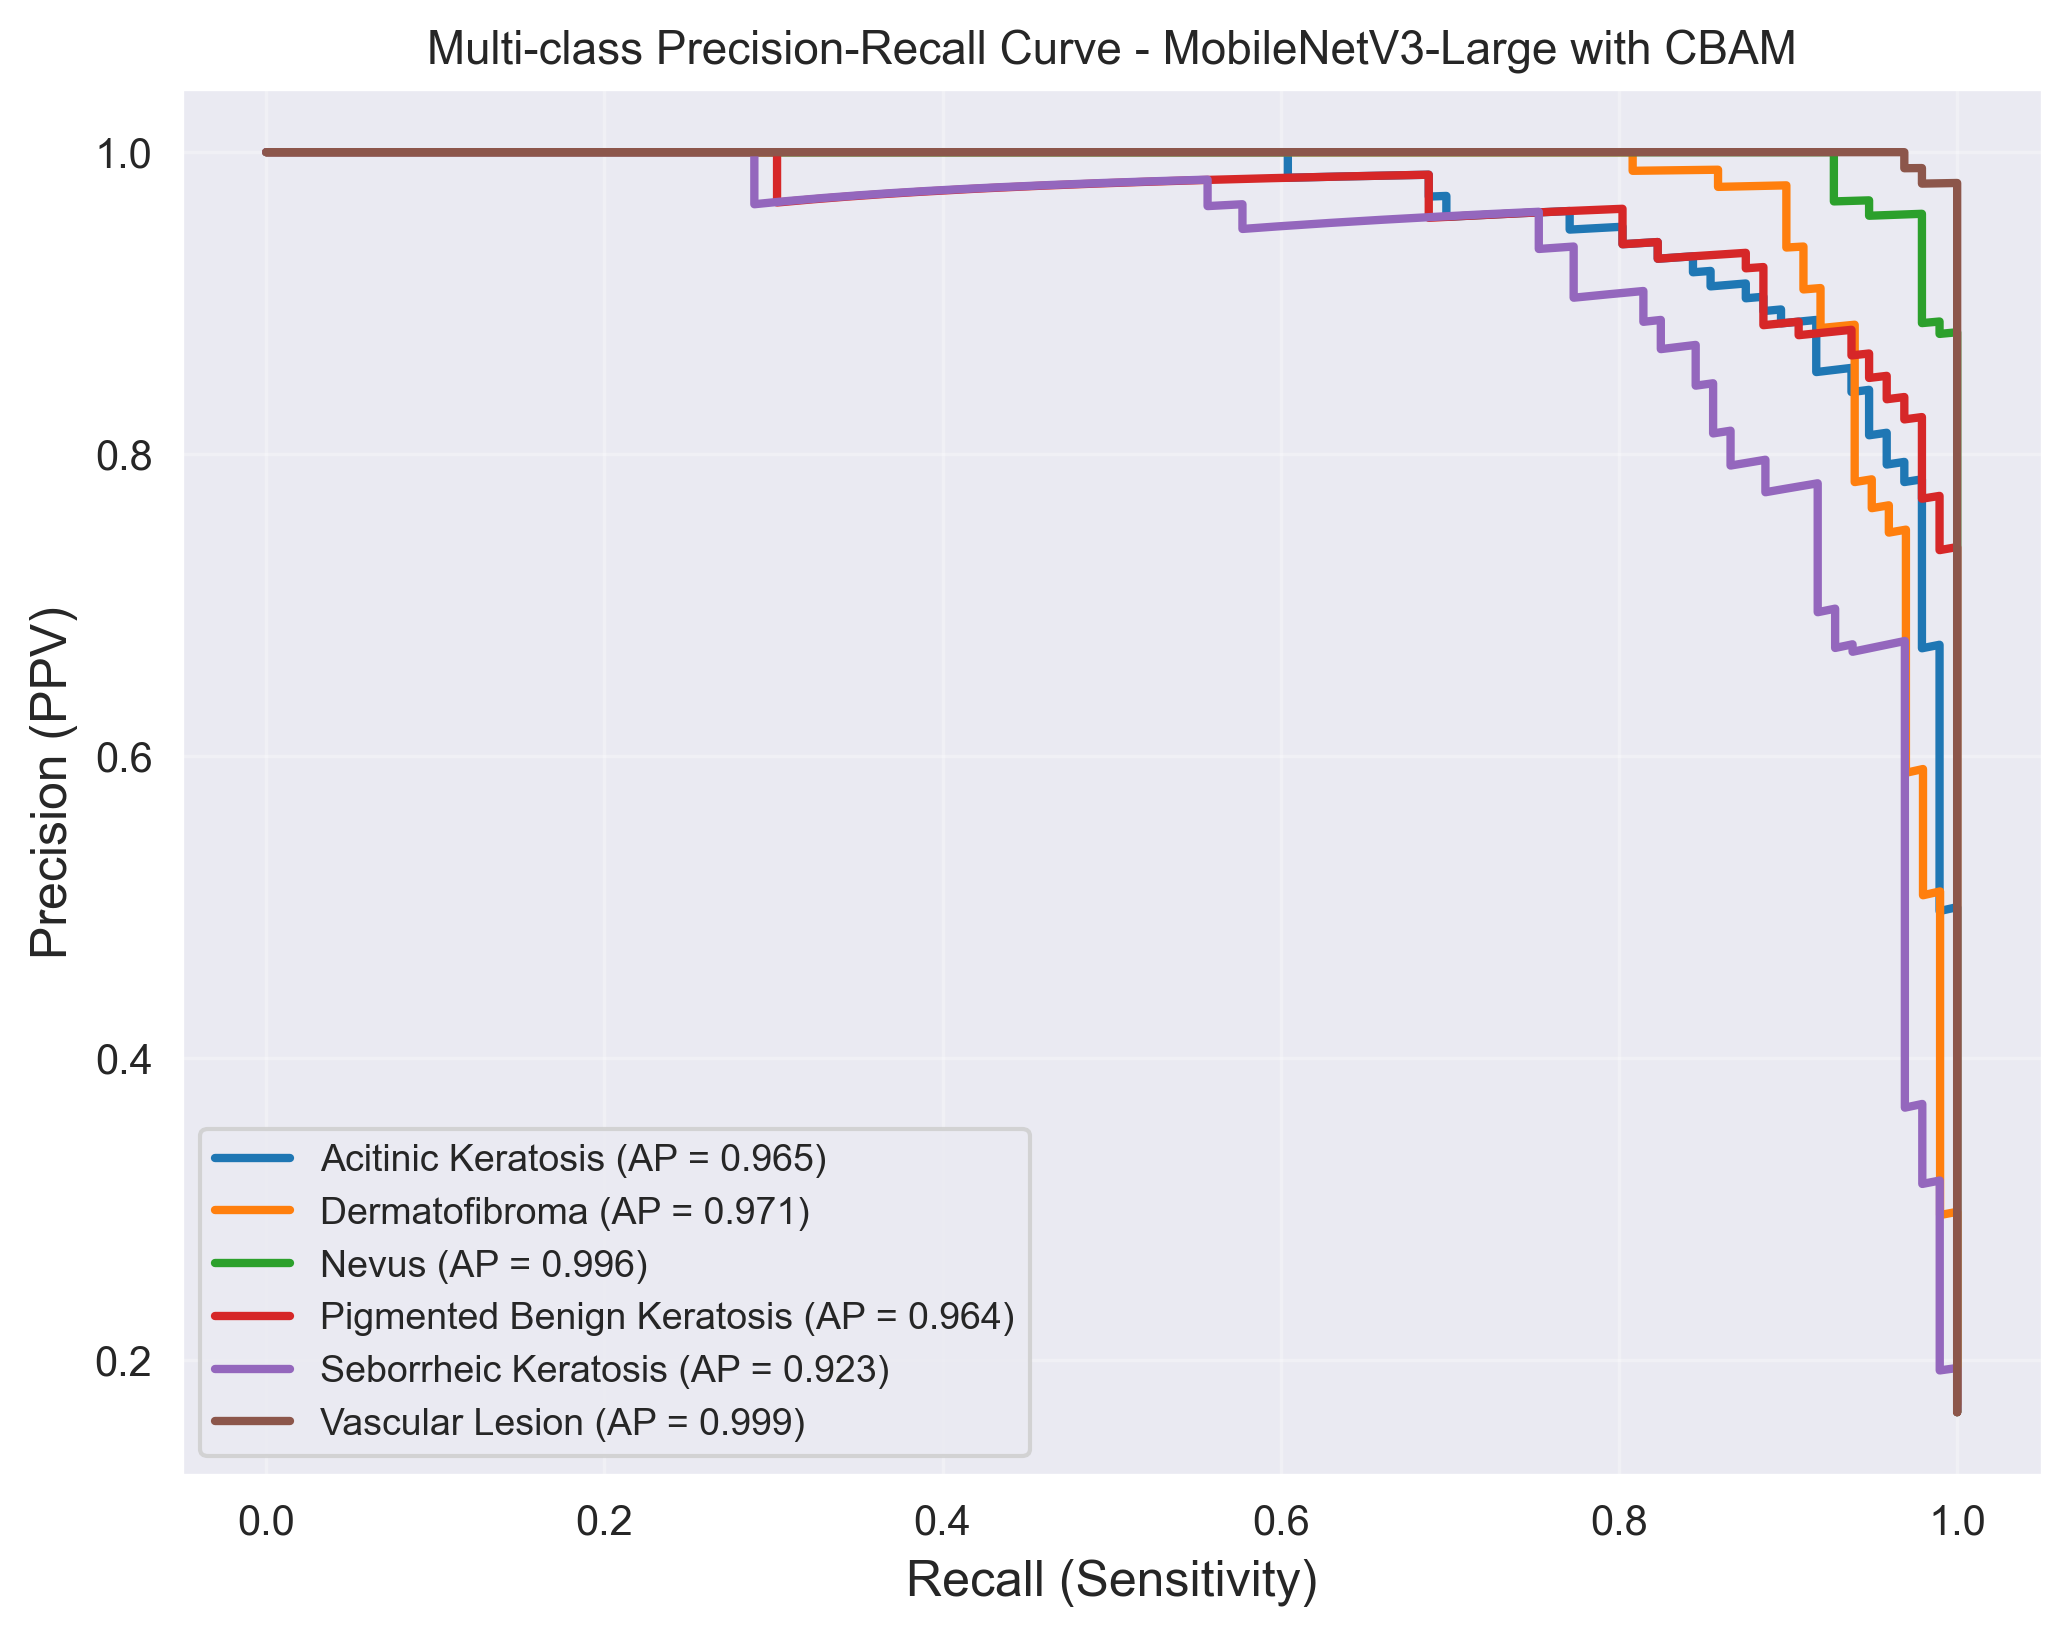

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Predict probabilities (NOT argmax)
y_score = model.predict(x_test)

# Convert true labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

y_true_bin = label_binarize(y_true, classes=range(n_classes))

precision = dict()
recall = dict()
avg_precision = dict()

# Compute PR curve and Average Precision (AP) for each class
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(
        y_true_bin[:, i], y_score[:, i]
    )
    avg_precision[i] = average_precision_score(
        y_true_bin[:, i], y_score[:, i]
    )

# Create high-quality figure
plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(recall[i], precision[i], linewidth=2,
             label=f"{classes[i]} (AP = {avg_precision[i]:.3f})")

plt.xlabel("Recall (Sensitivity)", fontsize=12)
plt.ylabel("Precision (PPV)", fontsize=12)
plt.title("Multi-class Precision-Recall Curve - MobileNetV3-Large with CBAM", fontsize=11)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

# Save high-resolution image
plt.savefig("precision_recall_curve.png", dpi=300, bbox_inches='tight')

plt.show()


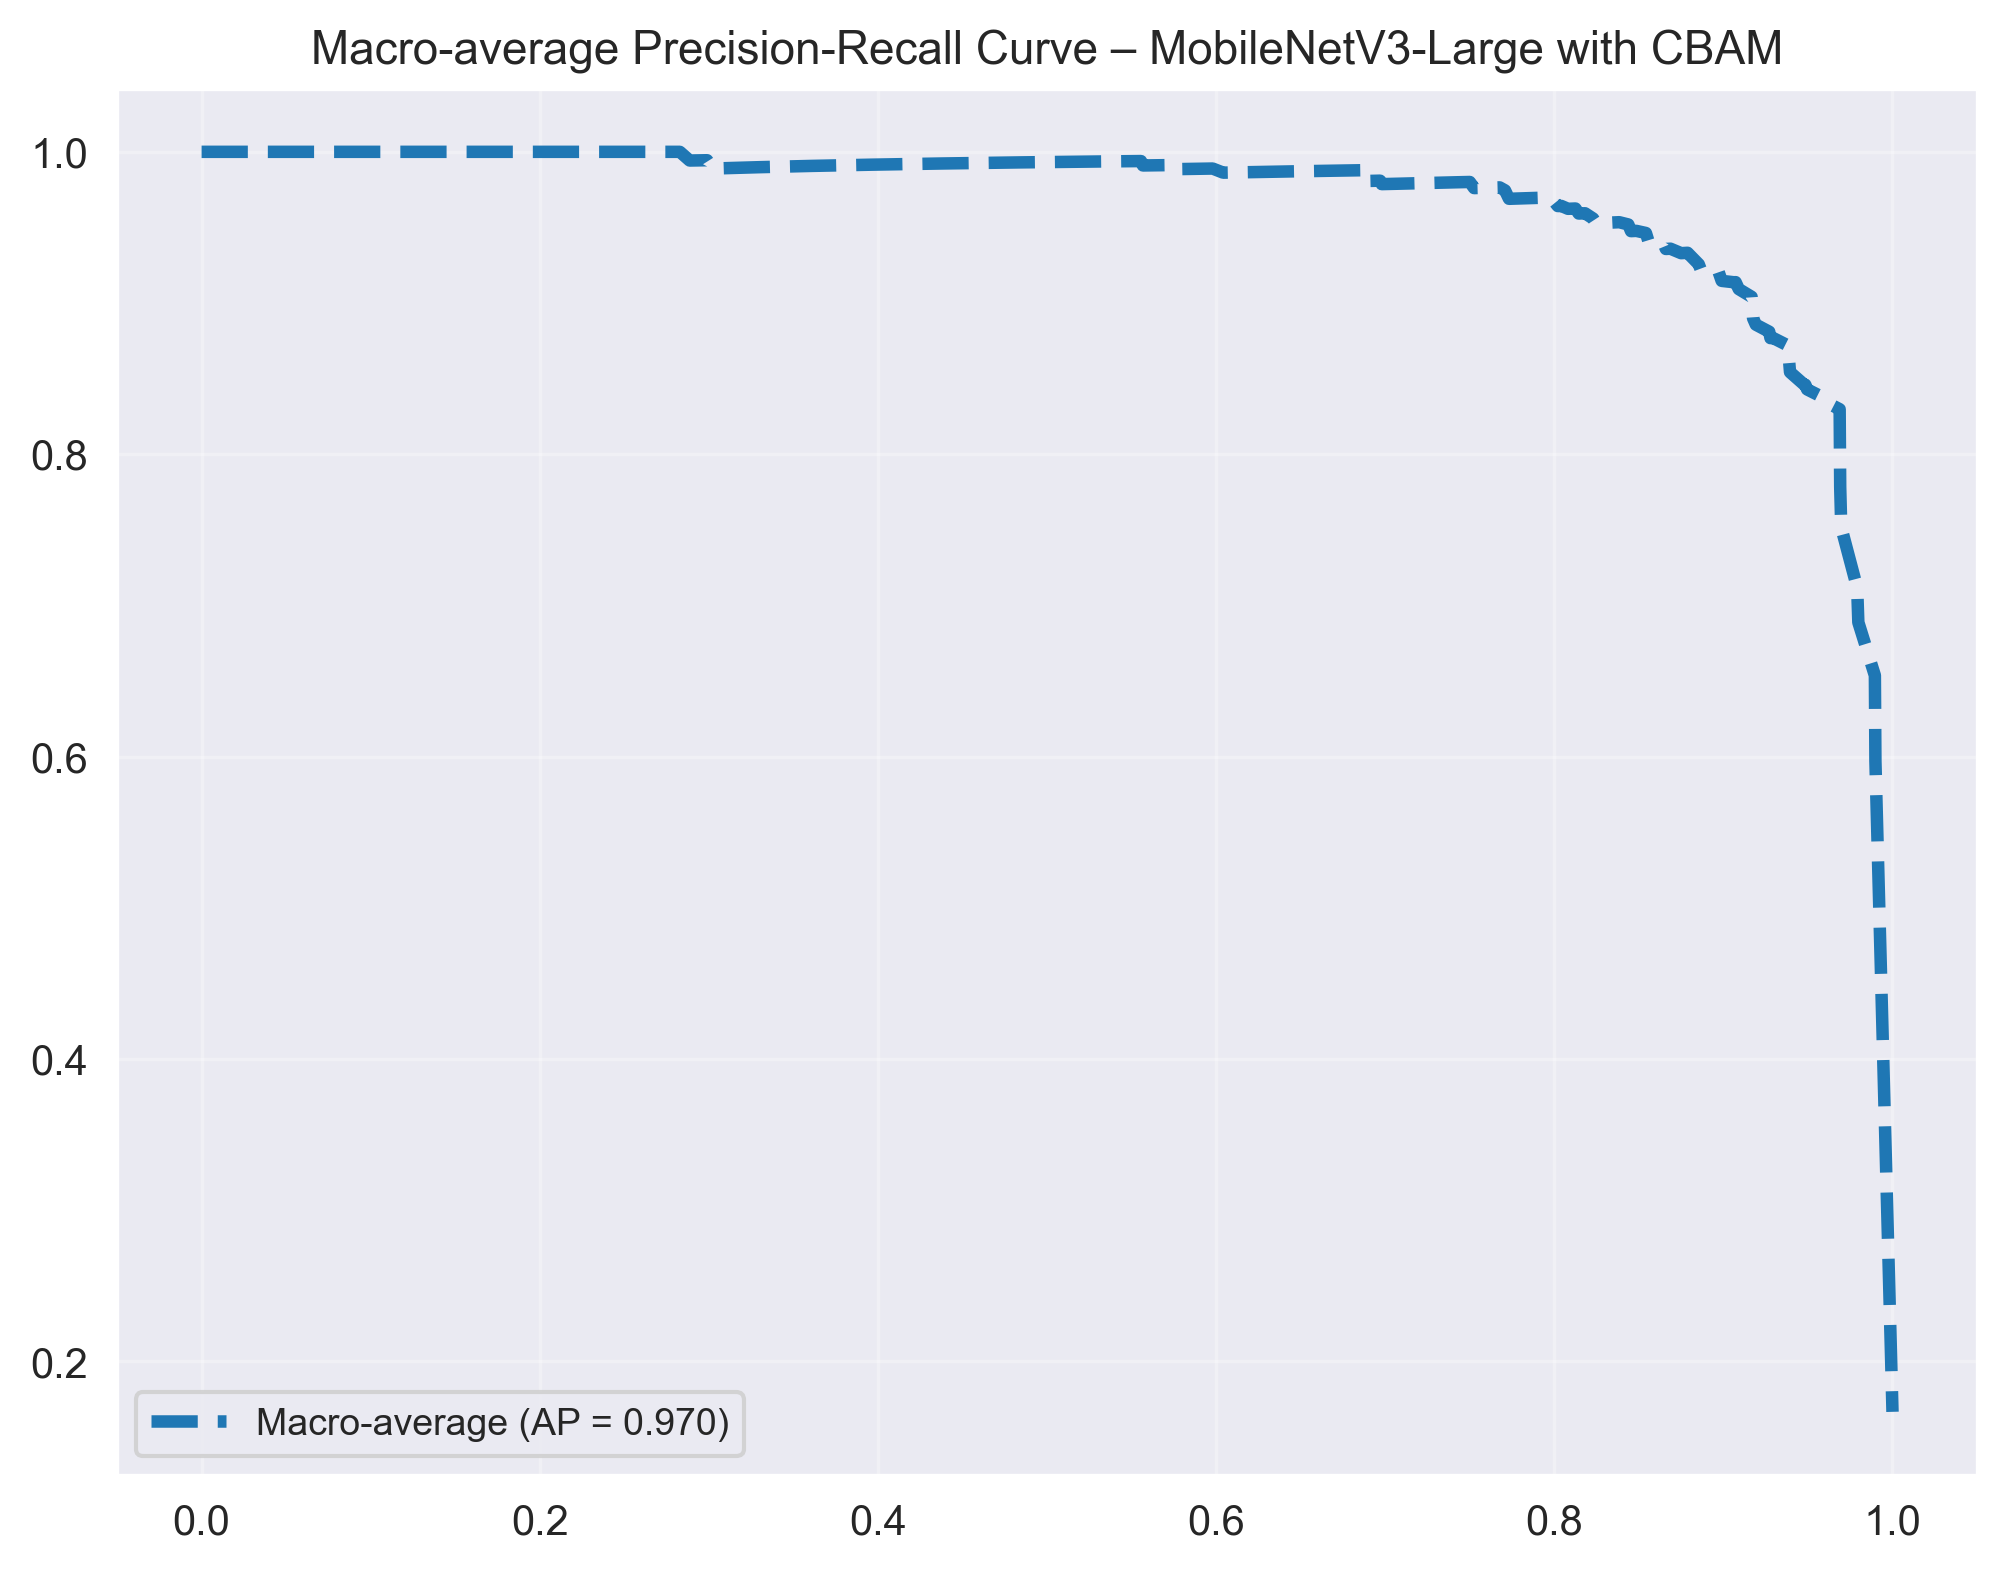

In [45]:
# Compute macro-average PR
all_recall = np.unique(np.concatenate([recall[i] for i in range(n_classes)]))
mean_precision = np.zeros_like(all_recall)

for i in range(n_classes):
    mean_precision += np.interp(all_recall, recall[i][::-1], precision[i][::-1])

mean_precision /= n_classes

macro_ap = np.mean(list(avg_precision.values()))
plt.figure(figsize=(8, 6), dpi=300)
plt.plot(all_recall, mean_precision, linestyle='--', linewidth=3,
         label=f"Macro-average (AP = {macro_ap:.3f})")
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)
plt.title("Macro-average Precision-Recall Curve – MobileNetV3-Large with CBAM", fontsize=11)

plt.show()

In [48]:
model.save("Weights/CBAM_mobilenetv3_model_final.h5")

In [49]:
model.save("Weights/CBAM_mobilenetv3_model_final.keras")

In [51]:
import pickle
with open("history_mobilenet_cbam.pkl", "wb") as f:
    pickle.dump(history.history, f)

In [52]:
import pickle

with open("history_mobilenet_cbam.pkl", "rb") as f:
    history = pickle.load(f)


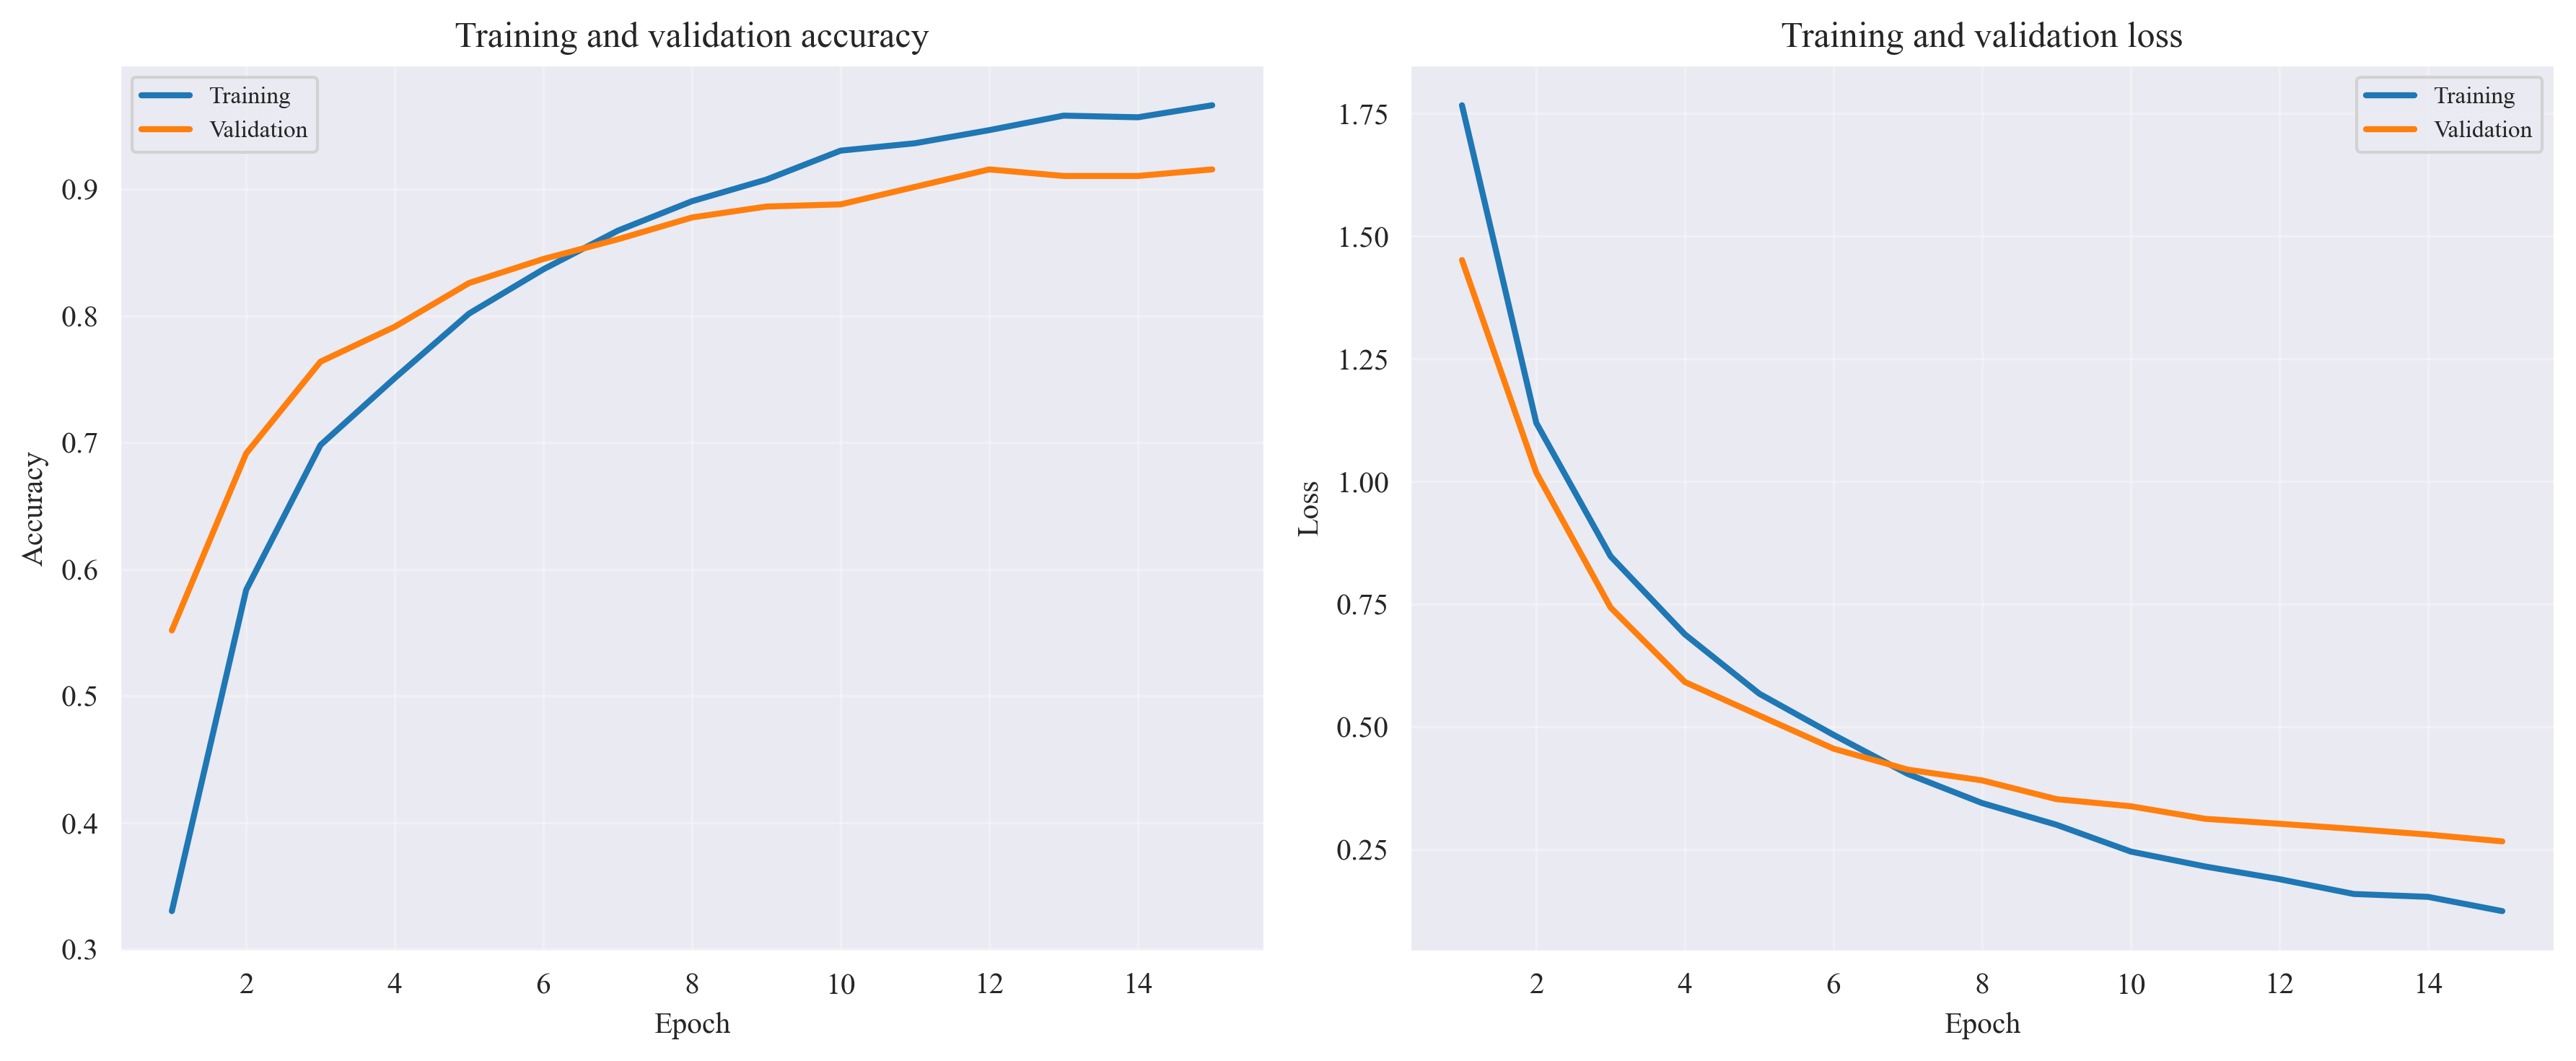

In [55]:
import matplotlib.pyplot as plt
import pickle

# load saved history
with open("history_mobilenet_cbam.pkl", "rb") as f:
    history = pickle.load(f)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 10

epochs_range = range(1, len(history['accuracy']) + 1)

plt.figure(figsize=(12, 5), dpi=300)

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['accuracy'], linewidth=2, label='Training')
plt.plot(epochs_range, history['val_accuracy'], linewidth=2, label='Validation')
plt.title("Training and validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['loss'], linewidth=2, label='Training')
plt.plot(epochs_range, history['val_loss'], linewidth=2, label='Validation')
plt.title("Training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("mobilenet_training_curves_ieee.png", dpi=300, bbox_inches='tight')
plt.show()
